# Homework 4 Worked Example: Corn Planted Acres and Last Year's Price

### AGEC 370: Agricultural Price Analysis

Click the badge below to open in Google Colab:

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/chuckgrigsby0/agec_370/blob/main/code/notebooks/hw04_example_corn_acres_regression.ipynb)

---

## Objective

Estimate how U.S. corn planted acres respond to last year's real corn price. Use logarithms so that the regression coefficient is an elasticity. Compare models with and without a time trend.

---

## How to Use This Notebook

1. Save a copy of this notebook to your Google Drive.
2. Run every cell in order from top to bottom.
3. Read the comments above each step before running the code. Review the output after running code cells.
4. Open the [Homework 4 notebook](https://colab.research.google.com/github/chuckgrigsby0/agec_370/blob/main/code/notebooks/hw04_hog_price_regression.ipynb). Complete the same steps with the hog data.

## Data Description

The file `corn_production_price.csv` has one row per year, 1913 to 2025. The price is the marketing year average, labeled by the year the marketing year starts (September to August). For example, the 2024 price is the average for September 2024 through August 2025.

| Column | Description | Units |
|---|---|---|
| `year` | Calendar year for production. Marketing year for price. | |
| `production_billion_bu` | U.S. corn production (USDA NASS) | Billion bushels |
| `nominal_price` | Marketing year average price received by U.S. corn producers (USDA NASS) | Dollars per bushel |
| `annual_avg_cpi` | Consumer Price Index for All Urban Consumers (CPI-U), all items, annual average (BLS) | Index (1982-84 = 100) |

The file `corn_planted_acres.csv` has one row per year, 1960 to 2025.

| Column | Description | Units |
|---|---|---|
| `year` | Calendar year | |
| `planted_acres_million` | U.S. corn planted acres (USDA NASS) | Million acres |

## Package and Data Loading

Import the libraries, load both files, calculate the real price, and add last year's real price. Then keep the years that have planted acres.

In [1]:
# Import data manipulation libraries
import pandas as pd
import numpy as np

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import the regression library
# 'smf' lets us write a regression as a formula, such as 'outcome ~ explanatory variable'
import statsmodels.formula.api as smf

In [2]:
# Load data from GitHub repository
base_url = "https://raw.githubusercontent.com/chuckgrigsby0/agec_370/main/data/hw/"
corn = pd.read_csv(base_url + "corn_production_price.csv")
planted = pd.read_csv(base_url + "corn_planted_acres.csv")

# Real price in 2025 dollars: real_price = (nominal_price / CPI_t) * CPI_2025
cpi_base_year = corn[corn['year'] == 2025]['annual_avg_cpi'].values[0]
corn['real_price'] = (corn['nominal_price'] / corn['annual_avg_cpi']) * cpi_base_year

# Last year's real price: shift(1) moves each value down one row, so each year sees the previous year's price.
# We do this on the full price series so that 1960 has a lagged price from 1959.
corn['real_price_lag1'] = corn['real_price'].shift(1)

# merge() lines up rows from two tables on a shared column. Only years in both tables are kept.
acres = planted.merge(corn[['year', 'production_billion_bu', 'real_price', 'real_price_lag1']], on='year')

print(f"Years in the acres models: {acres['year'].min()} to {acres['year'].max()} ({len(acres)} years)")
acres.head()

Years in the acres models: 1960 to 2025 (66 years)


,year,planted_acres_million,production_billion_bu,real_price,real_price_lag1
0,1960,81.425,3.906949,10.876453,11.616500
1,1961,65.919,3.597803,11.844057,10.876453
2,1962,65.017,3.606311,11.939608,11.844057
3,1963,68.771,4.019238,11.678325,11.939608
4,1964,65.823,3.484253,12.150752,11.678325


In [3]:
# Check: this cell runs without an error when the data loaded and merged correctly
assert acres['year'].is_monotonic_increasing, "The years should be in order from earliest to latest."
assert acres.notna().all().all(), "There should be no missing values after the merge."
print("Data loaded correctly.")

Data loaded correctly.


## Look at the Data First

### Why Logarithms

The natural logarithm, `np.log()`, rescales a variable so that equal percentage changes become equal distances. Key points:

- A change of 0.01 in a natural log is about a 1% change in the variable.
- In a *log-log regression*, the slope is an *elasticity*: the percentage change in the outcome for a 1% change in the explanatory variable.
- On a logarithmic axis, steady percentage growth plots as a straight line.

### Corn Production Over Time

The next plot uses a logarithmic axis.

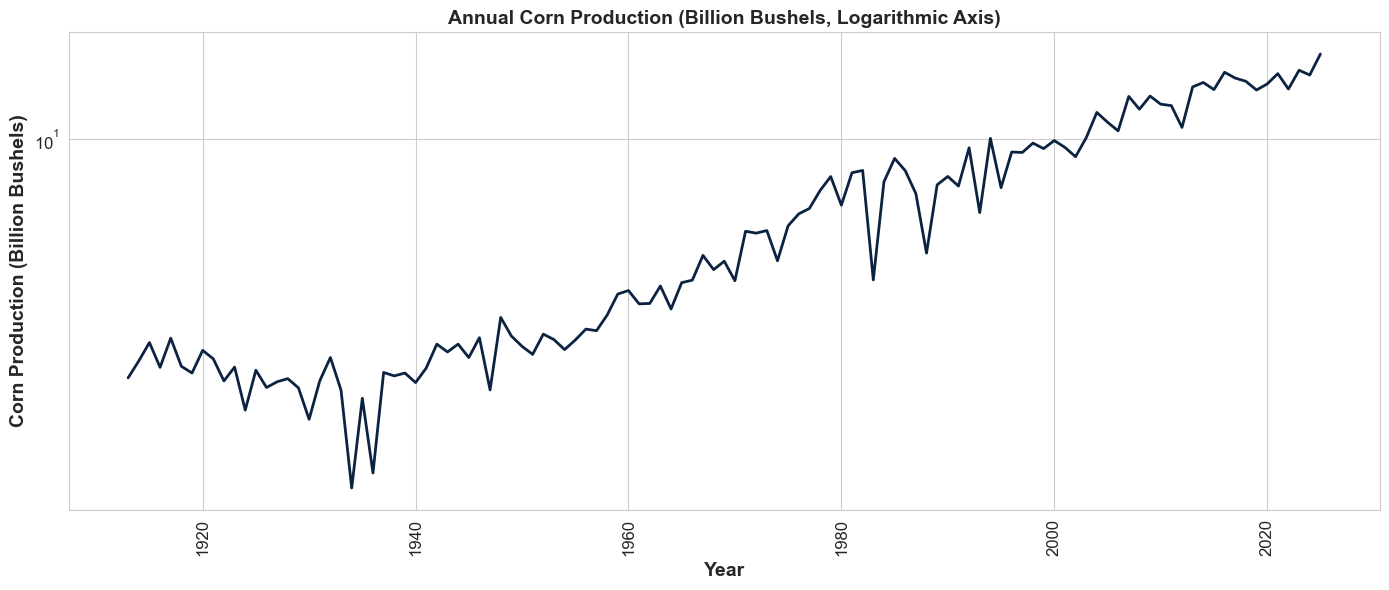

In [4]:
sns.set_style('whitegrid')

plt.figure(figsize=(14, 6))

sns.lineplot(data=corn, x='year', y='production_billion_bu', color='#0b2341', linewidth=2)

# The log scale spaces the y-axis by percentage change instead of by equal amounts
plt.yscale('log')

plt.title("Annual Corn Production (Billion Bushels, Logarithmic Axis)", fontsize=14, weight='bold')
plt.xlabel("Year", fontsize=14, weight='bold')
plt.ylabel("Corn Production (Billion Bushels)", fontsize=14, weight='bold')
plt.xticks(rotation=90, ha='center', fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

### Planted Acres and Last Year's Real Price: Levels

Each point is one year. `sns.regplot()` adds the fitted line from a simple regression.

Documentation: [Seaborn regplot](https://seaborn.pydata.org/generated/seaborn.regplot.html)

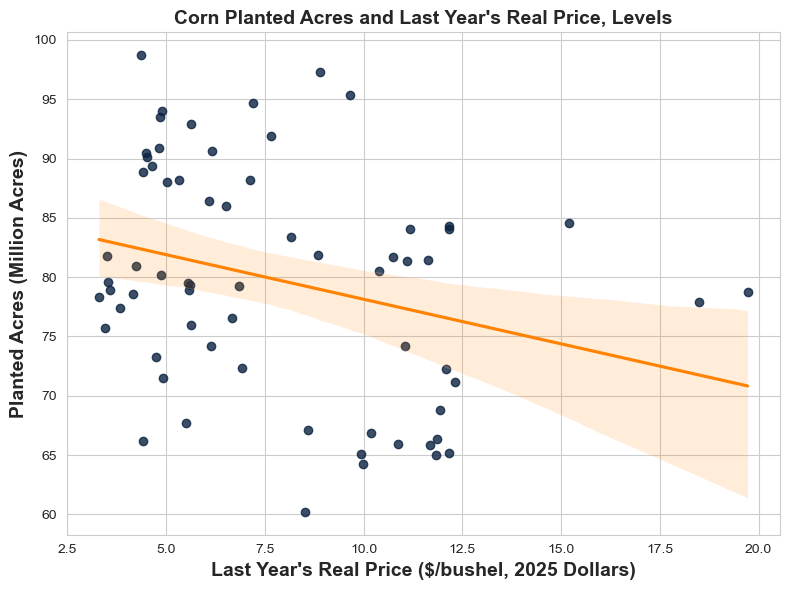

In [5]:
plt.figure(figsize=(8, 6))

sns.regplot(
    data=acres,
    x='real_price_lag1',               # explanatory variable
    y='planted_acres_million',         # outcome
    scatter_kws={'color': '#0b2341'},
    line_kws={'color': '#FF8200'}
)

plt.title("Corn Planted Acres and Last Year's Real Price, Levels", fontsize=14, weight='bold')
plt.xlabel("Last Year's Real Price ($/bushel, 2025 Dollars)", fontsize=14, weight='bold')
plt.ylabel("Planted Acres (Million Acres)", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

### Planted Acres and Last Year's Real Price: Logs

Create a natural log version of each variable.

In [6]:
# np.log() takes the natural logarithm of every value in a column
acres['ln_planted_acres'] = np.log(acres['planted_acres_million'])
acres['ln_real_price_lag1'] = np.log(acres['real_price_lag1'])

acres[['year', 'ln_planted_acres', 'ln_real_price_lag1']].head()

,year,ln_planted_acres,ln_real_price_lag1
0,1960,4.399682,2.452427
1,1961,4.188427,2.386600
2,1962,4.174649,2.471826
3,1963,4.230782,2.479861
4,1964,4.186969,2.457735


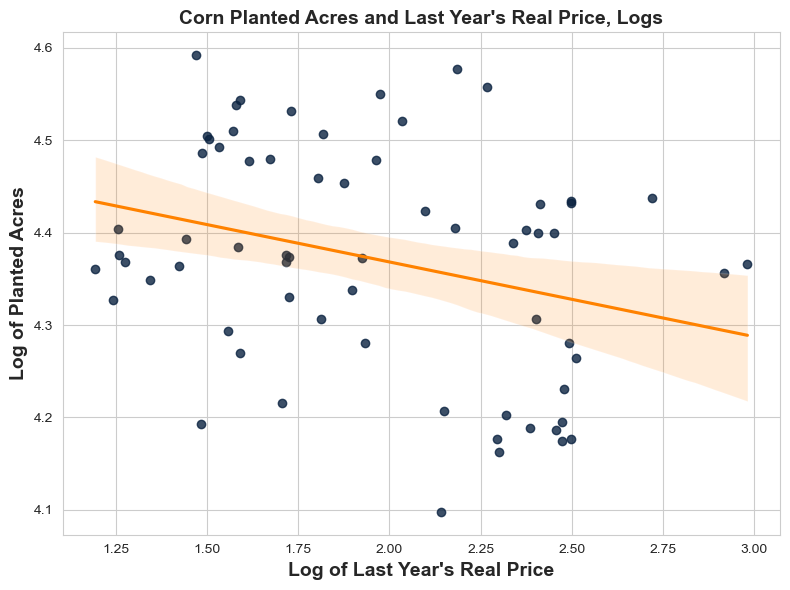

In [7]:
plt.figure(figsize=(8, 6))

sns.regplot(
    data=acres,
    x='ln_real_price_lag1',     # explanatory variable
    y='ln_planted_acres',       # outcome
    scatter_kws={'color': '#0b2341'},
    line_kws={'color': '#FF8200'}
)

plt.title("Corn Planted Acres and Last Year's Real Price, Logs", fontsize=14, weight='bold')
plt.xlabel("Log of Last Year's Real Price", fontsize=14, weight='bold')
plt.ylabel("Log of Planted Acres", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

## Regression of Acres on Last Year's Price

The fitted lines in the two plots above use price only. The models below also include the year.

Estimate two models with `smf.ols()`. In a formula, the outcome is on the left of `~` and the explanatory variables are on the right. Each model adds the year (a *time trend*). Planted acres rise over time with technology and farm size, whatever the price.

Part of last year's price is observed after planting (the marketing year runs from September to August), so it is a rough measure of the price signal.

- **Level-level:** `planted_acres_million ~ real_price_lag1 + year`. The price slope is million acres per one-dollar increase in price.
- **Log-log:** `ln_planted_acres ~ ln_real_price_lag1 + year`. The price slope is an elasticity.

In the homework, you will record guesses before you plot and estimate.

In [8]:
# Level-level model, with a time trend
level_model = smf.ols('planted_acres_million ~ real_price_lag1 + year', data=acres).fit()

# Log-log model, with a time trend
loglog_model = smf.ols('ln_planted_acres ~ ln_real_price_lag1 + year', data=acres).fit()

# tables[1] is the coefficient table
print(level_model.summary().tables[1])
print(loglog_model.summary().tables[1])

                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept       -1100.3039     87.710    -12.545      0.000   -1275.578    -925.030
real_price_lag1     1.4391      0.227      6.350      0.000       0.986       1.892
year                0.5866      0.043     13.523      0.000       0.500       0.673
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept            -10.7339      1.195     -8.980      0.000     -13.123      -8.345
ln_real_price_lag1     0.1477      0.025      5.984      0.000       0.098       0.197
year                   0.0074      0.001     12.775      0.000       0.006       0.009


In [9]:
# Pull the numbers we need out of the fitted models
elasticity = loglog_model.params['ln_real_price_lag1']   # price slope of the log-log model
p_value = loglog_model.pvalues['ln_real_price_lag1']     # p-value for that slope
r2_loglog = loglog_model.rsquared
r2_level = level_model.rsquared

print(f"Elasticity: {elasticity:.3f}")
print("p-value:", "below 0.0001" if p_value < 0.0001 else round(p_value, 4))
print(f"R-squared, log-log: {r2_loglog:.3f}")
print(f"R-squared, level-level: {r2_level:.3f}")

Elasticity: 0.148
p-value: below 0.0001
R-squared, log-log: 0.747
R-squared, level-level: 0.765


R-squared is the share of the variation in the outcome that the model accounts for. Models with different outcomes (acres and the log of acres) have R-squared values that are not directly comparable. Use each R-squared to judge its own model. Do not compare them across the two models.

## Interpreting the Elasticity

An elasticity multiplied by a percentage change in the explanatory variable gives the predicted percentage change in the outcome. This is a good approximation for small changes.

The *p-value* is the probability of an estimate at least this far from zero if the true slope were zero. A p-value below 0.05 is the usual cutoff for calling a slope statistically different from zero. A larger p-value means the data cannot rule out a slope of zero.

In [10]:
price_change = 10  # percent increase in last year's real price

# Predicted percentage change in planted acres = elasticity * percentage change in price
acres_change = elasticity * price_change
print(f"A {price_change}% increase in last year's real price is associated with a {acres_change:.1f}% change in planted acres.")

# Is the slope statistically different from zero at the 0.05 level?
significant = p_value < 0.05
print(f"Significant at the 0.05 level: {significant}")

A 10% increase in last year's real price is associated with a 1.5% change in planted acres.
Significant at the 0.05 level: True


## Why the Trend Matters

Three models show what the time trend does. Each uses the same years.

| Model | Explanatory variables |
|---|---|
| A | Last year's real price |
| B | Last year's real price, plus the year |
| C | The year only |

Model B is the log-log model estimated above.

In [11]:
# Model A: last year's price only
model_a = smf.ols('ln_planted_acres ~ ln_real_price_lag1', data=acres).fit()

# Model B: last year's price plus the year (the log-log model above)
model_b = loglog_model

# Model C: the year only
model_c = smf.ols('ln_planted_acres ~ year', data=acres).fit()

price_coef_a = model_a.params['ln_real_price_lag1']
price_coef_b = model_b.params['ln_real_price_lag1']
r2_a = model_a.rsquared
r2_b = model_b.rsquared
r2_c = model_c.rsquared

print(f"Last year's price, model A: coefficient {price_coef_a:.3f}, R-squared {r2_a:.3f}")
print(f"Last year's price, model B: coefficient {price_coef_b:.3f}, R-squared {r2_b:.3f}")
print(f"Year only, model C: R-squared {r2_c:.3f}")

Last year's price, model A: coefficient -0.081, R-squared 0.091
Last year's price, model B: coefficient 0.148, R-squared 0.747
Year only, model C: R-squared 0.603


### Read the Three Models

Compare the price coefficient across models A and B, and compare the three R-squared values. The homework asks you to make the same comparisons with hog data.

### Summary of Answers

Run the cell below to print the answers in one table.

In [12]:
# Collect the answers computed above in one table
summary = pd.Series({
    'Years in the acres models': len(acres),
    'Level-level R-squared': round(r2_level, 3),
    'Elasticity, log-log with trend': round(elasticity, 3),
    'R-squared, log-log with trend': round(r2_loglog, 3),
    'Acres change for a 10% price rise (%)': round(acres_change, 1),
    'Significant at 0.05': significant,
    'Price coefficient, model A (no trend)': round(price_coef_a, 3),
    'R-squared, model A': round(r2_a, 3),
    'R-squared, model B': round(r2_b, 3),
    'R-squared, model C (trend only)': round(r2_c, 3),
}, name='Answer', dtype=object)  # object type keeps whole numbers as whole numbers
summary.to_frame()

,Answer
Years in the acres models,66
Level-level R-squared,0.765
"Elasticity, log-log with trend",0.148
"R-squared, log-log with trend",0.747
Acres change for a 10% price rise (%),1.5
Significant at 0.05,True
"Price coefficient, model A (no trend)",-0.081
"R-squared, model A",0.091
"R-squared, model B",0.747
"R-squared, model C (trend only)",0.603


## Next Step

Open the [Homework 4 notebook](https://colab.research.google.com/github/chuckgrigsby0/agec_370/blob/main/code/notebooks/hw04_hog_price_regression.ipynb) and complete the same steps with the hog data.